# Evaluations

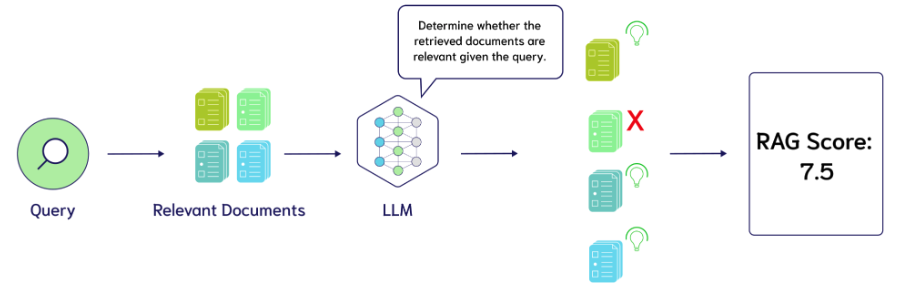

# [RAGAs - Evaluations](https://docs.ragas.io/en/stable/)

이 다이어그램은 질문-답변(QA) 데이터를 자동으로 만들고 개선하는 과정을 보여줍니다.

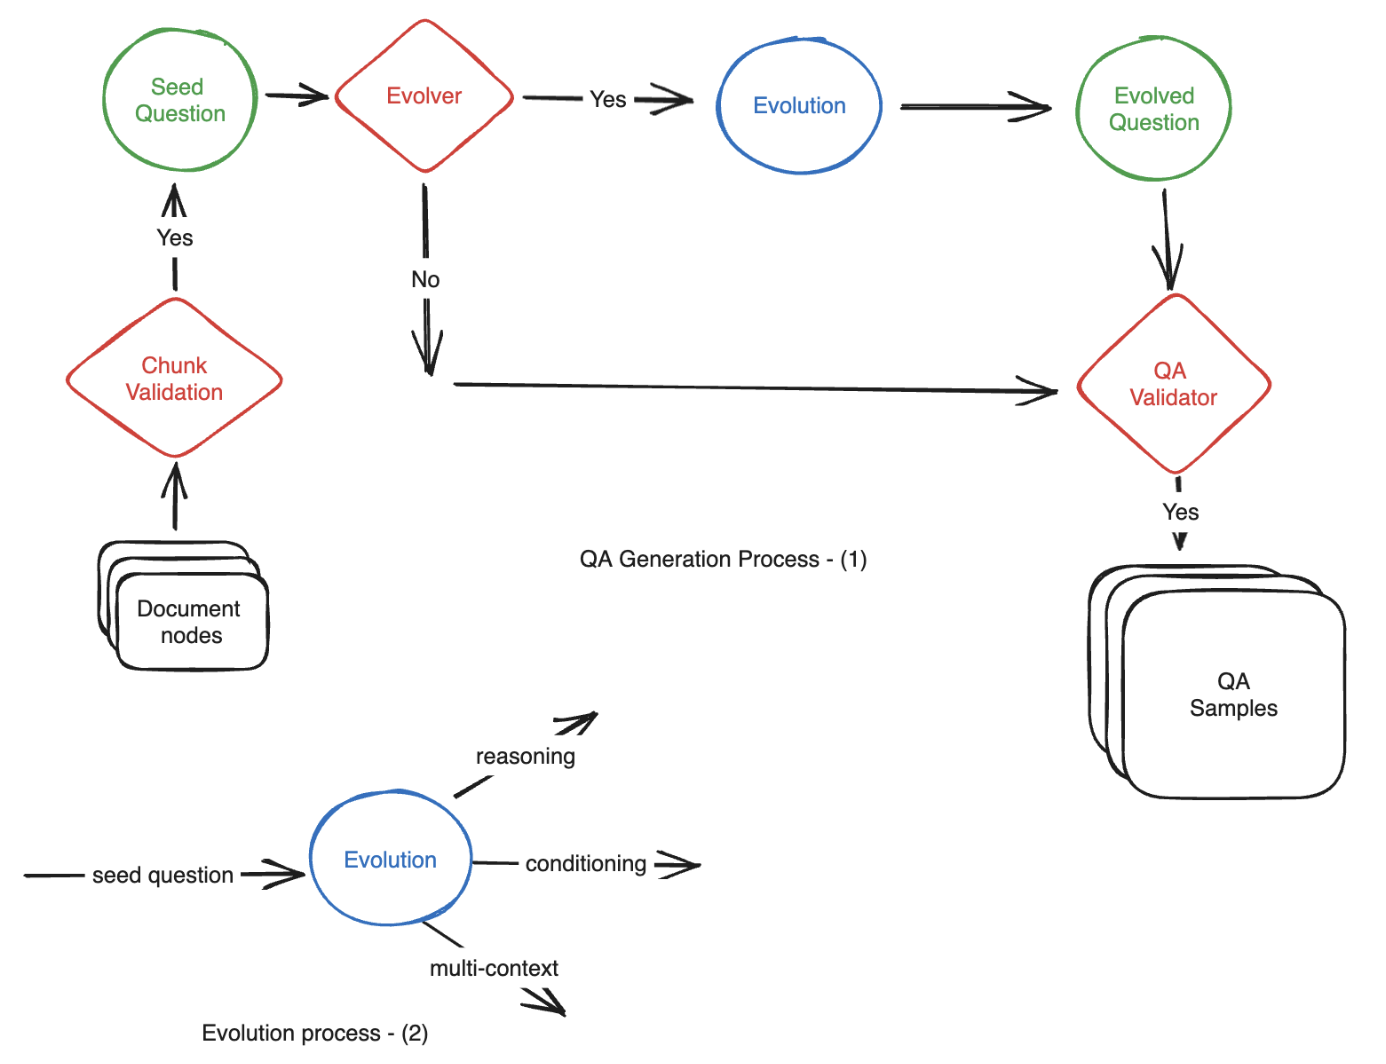

## Testset Generation Process

### (1) QA Generation Process

1. `Seed Question (시작 질문)`: 처음 만든 기본 질문으로 시작합니다
2. `Evolver (진화 판단)`: 이 질문을 더 발전시킬지 결정합니다
    - Yes → Evolution (질문 진화) 단계로 이동
    - No → 바로 QA Validator로 이동
3. `Evolution (질문 진화)`: 질문을 더 복잡하고 다양하게 변형합니다
4. `Evolved Question (진화된 질문)`: 개선된 새로운 질문이 생성됩니다
5. `QA Validator (검증)`: 만들어진 질문-답변 쌍이 좋은 품질인지 확인합니다
    - Yes → QA Samples (완성된 데이터)에 저장
6. `Chunk Validation (문서 검증)`: Document nodes(문서 조각들)이 유효한지 확인한 후, 다시 Seed Question으로 돌아가 반복합니다

### (2) Evolution Process
질문을 진화시킬 때 세 가지 방법을 사용합니다:

- `Reasoning (추론)`: 논리적 사고가 필요한 질문으로 만들기
- `Conditioning (조건 추가)`: 특정 조건을 추가한 질문으로 만들기
- `Multi-context (다중 맥락)`: 여러 정보를 종합해야 하는 질문으로 만들기

핵심: 간단한 질문에서 시작해서 점점 더 어렵고 유용한 질문을 자동으로 만들어내는 순환 시스템입니다!

## [평가 데이터셋 생성](https://docs.ragas.io/en/latest/concepts/test_data_generation/)

### 문서 전처리

In [1]:
from langchain_community.document_loaders import PDFPlumberLoader

# 문서 로더 생성
DATA_PATH = "./data/"
loader = PDFPlumberLoader(DATA_PATH+"SPRI_AI_Brief_2023년12월호_F.pdf")

# 문서 로딩
documents = loader.load()

In [2]:
print(f"PDF 페이지 수: {len(documents)}")

PDF 페이지 수: 23


> PDF 파일 내용

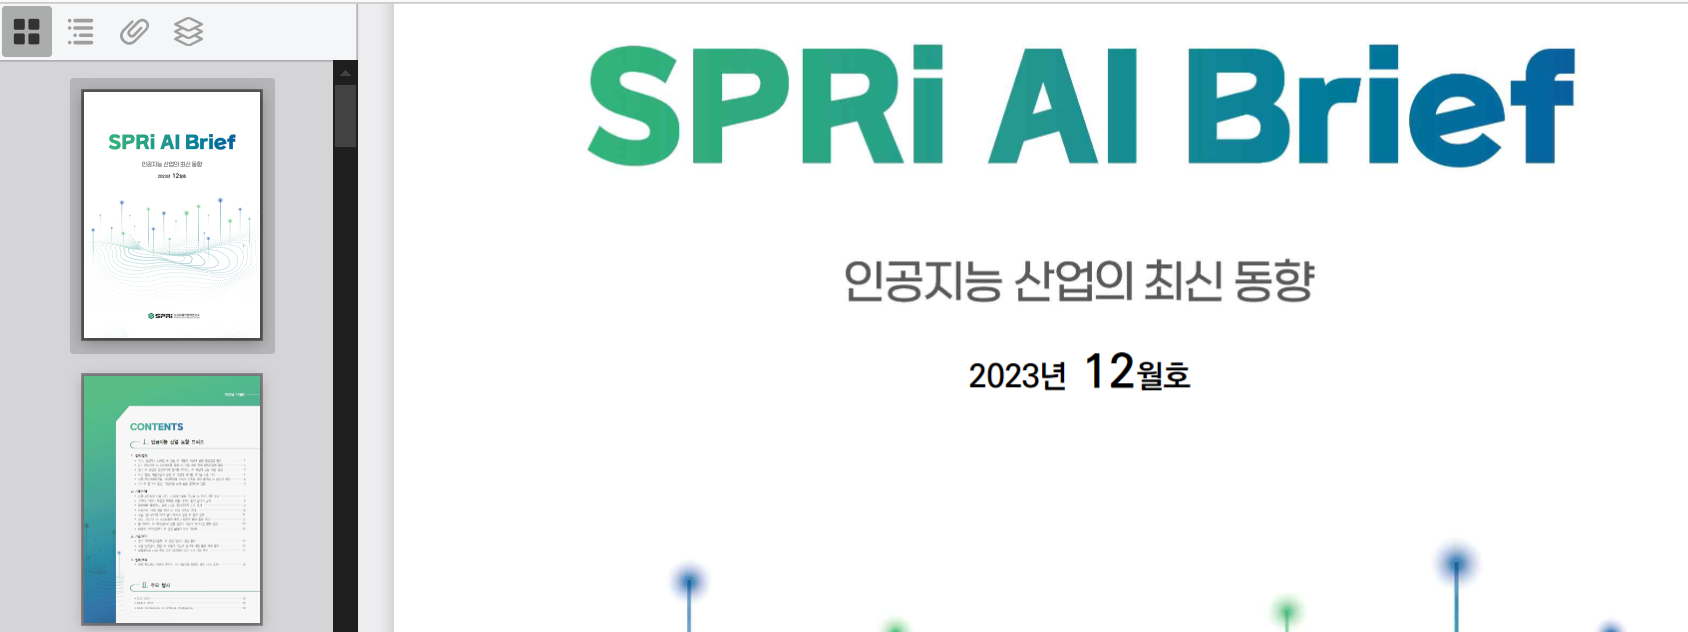

In [3]:
# 시작, 목차, 끝 페이지 제외
documents = documents[3:-1]

# 문서의 페이지수
len(documents)

19

> metadata 처리 

In [4]:
documents[0].metadata

{'source': './data/SPRI_AI_Brief_2023년12월호_F.pdf',
 'file_path': './data/SPRI_AI_Brief_2023년12월호_F.pdf',
 'page': 3,
 'total_pages': 23,
 'Author': 'dj',
 'Creator': 'Hwp 2018 10.0.0.13462',
 'Producer': 'Hancom PDF 1.3.0.542',
 'CreationDate': "D:20231208132838+09'00'",
 'ModDate': "D:20231208132838+09'00'",
 'PDFVersion': '1.4'}

In [5]:
# metadata 설정(source에 파일 경로와 페이지 번호를 남김)
for doc in documents:
    doc.metadata["source"] = f"file path: {doc.metadata["file_path"]} & page no: {doc.metadata['page']}"


In [6]:
documents[0].metadata

{'source': 'file path: ./data/SPRI_AI_Brief_2023년12월호_F.pdf & page no: 3',
 'file_path': './data/SPRI_AI_Brief_2023년12월호_F.pdf',
 'page': 3,
 'total_pages': 23,
 'Author': 'dj',
 'Creator': 'Hwp 2018 10.0.0.13462',
 'Producer': 'Hancom PDF 1.3.0.542',
 'CreationDate': "D:20231208132838+09'00'",
 'ModDate': "D:20231208132838+09'00'",
 'PDFVersion': '1.4'}

> page_content 확인 

In [7]:
print(documents[0].page_content[:300])

1. 정책/법제 2. 기업/산업 3. 기술/연구 4. 인력/교육
미국, 안전하고 신뢰할 수 있는 AI 개발과 사용에 관한 행정명령 발표
KEY Contents
n 미국 바이든 대통령이 ‘안전하고 신뢰할 수 있는 AI 개발과 사용에 관한 행정명령’에 서명하고
광범위한 행정 조치를 명시
n 행정명령은 △AI의 안전과 보안 기준 마련 △개인정보보호 △형평성과 시민권 향상 △소비자
보호 △노동자 지원 △혁신과 경쟁 촉진 △국제협력을 골자로 함
£바이든 대통령, AI 행정명령 통해 안전하고 신뢰할 수 있는 AI 개발과 활용 추진
n 미국 바


### 평가 데이터셋

#### [문장을 생성하는 LLM](https://platform.openai.com/docs/models)
- [OpenAI Key 발급](https://platform.openai.com/api-keys)

In [8]:
from dotenv import load_dotenv 

# .env 파일에 있는 데이터를 환경변수에 등록해주는 함수 
load_dotenv()

True

In [9]:
# RAGAS 0.3.9의 llm_factory(InstructorLLM)는 프롬프트 생성 경로에서
# 'agenerate_prompt' AttributeError가 날 수 있어 ChatOpenAI + RAGAS 래퍼를 사용합니다.
from langchain_openai import ChatOpenAI
from ragas.llms.base import LangchainLLMWrapper

# 질문/답변 생성, NER 변환, 프롬프트 한국어 변환에 공통으로 사용할 LLM
generator_chat_llm = ChatOpenAI(
    model="gpt-4o-mini",
    temperature=0,
)

# LangChain LLM을 그대로 넘기면 ```json 코드펜스를 RAGAS가 직접 파싱하지 못할 수 있습니다.
# LangchainLLMWrapper를 쓰면 RAGAS의 JSON 추출/재시도 파서가 적용됩니다.
generator_llm = LangchainLLMWrapper(generator_chat_llm)


#### [Embedding model](https://platform.openai.com/docs/guides/embeddings/embedding-models#embedding-models)

In [10]:
# RAGAS 0.3.9의 OpenAIEmbeddings 사용 (OpenAI client 필요)
from ragas.embeddings import OpenAIEmbeddings
from openai import OpenAI

# Embedding model -> 문장을 벡터로 변환하는 모델...
generator_embeddings = OpenAIEmbeddings(
    # OpenAI client 생성 (환경변수의 OPENAI_API_KEY를 자동으로 사용)
    client=OpenAI(),
    model="text-embedding-3-small"
)

#### 페르소나 정의(중요)
> 어떤 질문/답변 쌍을 만들지 정의함 

In [11]:
from ragas.testset.persona import Persona

personas = [
    Persona(
        name="AI Specialist",
        # 대규모 언어 모델(LLM)이 생성한 응답이 논리적으로 일관성 있고 윤리적으로 타당한지 평가하는 전문가.
        role_description="""
        A professional who evaluates whether the responses generated by large language models (LLMs)
        are logically coherent and ethically sound.
        """,
    ),
    Persona(
        name="AI Policy Analyst",
        # AI 규제, 거버넌스, 산업 영향 관점에서 문서의 정책적 함의를 비교·분석하는 전문가.
        role_description="""
        A policy and business analyst who compares AI regulations, governance requirements,
        market impacts, and adoption risks from government and enterprise perspectives.
        """,
    ),
]


#### 학습용 데이터를 만드는 객체

In [12]:
from ragas.testset import TestsetGenerator

# 학습용 데이터를 만드는 객체
generator = TestsetGenerator(
    llm=generator_llm, embedding_model=generator_embeddings, 
    persona_list=personas
)

문서 그래프 변환:
> single-hop 질문은 엔티티만 있어도 만들 수 있지만, multi-hop 질문은 문서/청크 사이의 관계가 필요합니다.
> `default_transforms`에서 요약, 테마, NER, 임베딩, 유사도/겹침 관계를 만들되, RAGAS 0.3.9에서 JSON 코드펜스 때문에 실패하기 쉬운 `CustomNodeFilter` 단계는 제외합니다. 생성 LLM은 RAGAS 래퍼를 거쳐 코드펜스가 붙은 JSON도 파싱되도록 합니다.


In [13]:
from ragas.testset.transforms import default_transforms
from ragas.testset.transforms.filters import CustomNodeFilter


def remove_custom_node_filter(transform_steps):
    return [
        transform
        for transform in transform_steps
        if not isinstance(transform, CustomNodeFilter)
    ]


# Multi-hop 질문 생성을 위해 요약/테마/엔티티/관계 정보를 함께 생성합니다.
# CustomNodeFilter는 일부 모델이 ```json 코드펜스를 반환할 때 ValidationError가 날 수 있어 제외합니다.
transforms = remove_custom_node_filter(
    default_transforms(
        documents[:],
        llm=generator_llm,
        embedding_model=generator_embeddings,
    )
)


질문 Synthesizer 구성
> RAGAS 0.3.9 기본 synthesizer 중 single-hop specific, multi-hop specific, multi-hop abstract를 섞어 더 다양한 평가 질문을 생성합니다.
>
> - `SingleHopSpecificQuerySynthesizer`: 한 문맥에서 특정 사실을 묻는 질문
> - `MultiHopSpecificQuerySynthesizer`: 엔티티가 겹치는 둘 이상의 문맥을 연결해야 하는 질문
> - `MultiHopAbstractQuerySynthesizer`: 유사한 주제/테마를 가진 여러 문맥을 종합해야 하는 질문
>
> 조건형 질문과 도메인 외 질문은 RAGAS 기본 synthesizer가 아니므로, 아래에서 수동 hard case로 추가합니다.


In [14]:
from ragas.testset.synthesizers.multi_hop.abstract import (
    MultiHopAbstractQuerySynthesizer,
)
from ragas.testset.synthesizers.multi_hop.specific import (
    MultiHopSpecificQuerySynthesizer,
)
from ragas.testset.synthesizers.single_hop.specific import (
    SingleHopSpecificQuerySynthesizer,
)

distribution = [
    (SingleHopSpecificQuerySynthesizer(llm=generator_llm), 0.4),
    (MultiHopSpecificQuerySynthesizer(llm=generator_llm), 0.3),
    (MultiHopAbstractQuerySynthesizer(llm=generator_llm), 0.3),
]

for query, _ in distribution:
    prompts = await query.adapt_prompts("korean", llm=generator_llm)
    query.set_prompts(**prompts)


#### 평가 데이터셋 생성

#### 테스트셋 규모와 질문 유형

강의 중에는 실행 시간과 API 비용을 고려해 10건으로 흐름을 먼저 확인합니다. 실제 서비스 평가에서는 질문 유형과 길이를 더 다양하게 만들고, 최소 수십 건 이상으로 늘려 점수 분포를 봅니다.

아래에서 조건형/도메인 외 hard case를 추가하므로 최종 저장 행 수는 `TESTSET_SIZE`보다 커집니다.


In [15]:
TESTSET_SIZE = 10

# 실습/과제에서는 30 이상으로 늘려 평가 표본을 확장해 봅니다.
TESTSET_SIZE


10

In [16]:
dataset = generator.generate_with_langchain_docs(
    documents[:],
    testset_size=TESTSET_SIZE, # 총 몇개의 질문/답변 쌍을 만들지
    transforms=transforms,
    query_distribution=distribution,
)


Applying HeadlinesExtractor:   0%|          | 0/19 [00:00<?, ?it/s]

Applying HeadlineSplitter:   0%|          | 0/19 [00:00<?, ?it/s]

Applying SummaryExtractor:   0%|          | 0/19 [00:00<?, ?it/s]

Applying EmbeddingExtractor:   0%|          | 0/19 [00:00<?, ?it/s]

c:\dev\course\course_rag\4. RAG Evaluations\.venv\Lib\site-packages\ragas\testset\transforms\base.py:202: UserWarning: Using sync embedding model OpenAIEmbeddings in async context. This may impact performance. Consider using an async-compatible embedding model for better performance.
  property_name, property_value = await self.extract(node)


...

Applying NERExtractor:   0%|          | 0/48 [00:00<?, ?it/s]

Applying CosineSimilarityBuilder:   0%|          | 0/1 [00:00<?, ?it/s]

Applying OverlapScoreBuilder:   0%|          | 0/1 [00:00<?, ?it/s]

Generating Scenarios:   0%|          | 0/3 [00:00<?, ?it/s]

Generating Samples:   0%|          | 0/10 [00:00<?, ?it/s]

#### 생성된 데이터셋 확인

In [17]:
eval_dataset = dataset.to_evaluation_dataset()

In [18]:
print("Query:", eval_dataset[0].user_input)
print("Reference:", eval_dataset[0].reference)

Query: 바이든 대통령의 행정명령은 AI 개발과 사용에 대해 어떤 내용을 포함하고 있습니까?
Reference: 바이든 대통령이 서명한 '안전하고 신뢰할 수 있는 AI 개발과 사용에 관한 행정명령'은 AI의 안전과 보안 기준 마련, 개인정보 보호 등 광범위한 행정 조치를 명시하고 있습니다.


In [19]:
import pandas as pd

# Testset.to_list()를 사용하면 RAGAS가 생성한 질문의 synthesizer_name까지 보존할 수 있습니다.
test_df = pd.DataFrame(dataset.to_list())

category_by_synthesizer = {
    "single_hop_specific_query_synthesizer": "single_hop_specific",
    "multi_hop_specific_query_synthesizer": "multi_hop_specific",
    "multi_hop_abstract_query_synthesizer": "multi_hop_abstract",
}

test_df["query_category"] = (
    test_df["synthesizer_name"]
    .map(category_by_synthesizer)
    .fillna("ragas_generated")
)

test_df.shape


(10, 8)

#### 까다로운 평가 문항 추가

자동 생성 질문만으로는 부족한 실패 유형을 직접 추가합니다. 조건형 질문은 문맥을 읽고 조건을 판별해야 하고, 도메인 외 질문은 검색 문서에 없는 정보를 억지로 답하지 않는지 확인합니다.


In [20]:
def reference_contexts(*document_indices):
    return [documents[index].page_content for index in document_indices]


hard_eval_cases = [
    {
        "user_input": "AI 행정명령과 G7 국제 행동강령을 비교해, 둘 다 공통으로 요구하는 위험 관리 조치 2가지와 G7 행동강령에 더 구체적으로 나온 조치 1가지를 구분해서 답하세요.",
        "reference_contexts": reference_contexts(0, 1),
        "reference": "두 문서 모두 첨단 AI 시스템의 위험을 평가하고 완화하는 조치와 투명성/책임성 강화를 요구합니다. 미국 AI 행정명령은 강력한 AI 시스템 개발 기업이 안전 테스트 결과와 주요 정보를 미국 정부와 공유하도록 요구하고, 안전성·신뢰성 확인 표준 및 AI 생성 콘텐츠 표시 표준 마련을 추진합니다. G7 국제 행동강령은 AI 수명주기 전반의 위험 평가와 완화, 정보공유와 이해관계자 협력, 보안 통제, 워터마크 등 콘텐츠 인증과 출처 확인 메커니즘을 더 구체적으로 제시합니다.",
        "persona_name": "AI Policy Analyst",
        "query_style": "CONDITIONAL_COMPARISON",
        "query_length": "LONG",
        "synthesizer_name": "manual_hard_case",
        "query_category": "conditional_multi_hop",
    },
    {
        "user_input": "EU AI 법 협상에서 프랑스, 독일, 이탈리아의 제안이 '기반모델 전반 규제 반대'와 '자율 행동강령 의무화' 조건을 모두 만족한다면, 감독기관은 준수 여부와 제재를 어떻게 다루어야 하나요?",
        "reference_contexts": reference_contexts(5),
        "reference": "프랑스, 독일, 이탈리아는 기반모델 전반 규제가 기술 중립적이고 위험 기반의 AI 규제 원칙에 어긋난다고 보고, 특정 용도로 사용될 수 있는 AI 시스템에 대한 규제를 요구했습니다. 동시에 자발적인 행동강령을 도입하고 준수를 의무화하며, 기반모델 개발기업에 머신러닝 기술 정보와 모델의 기능·한계를 요약한 모델 카드 작성을 요구했습니다. 감독기관은 모델 카드를 바탕으로 행동강령 준수 여부를 확인하되, 위반 시 즉시 제재하지 않고 위반행위 분석과 영향 평가를 시행한 뒤 제재하는 방식이 제안되었습니다.",
        "persona_name": "AI Policy Analyst",
        "query_style": "CONDITIONAL_REASONING",
        "query_length": "LONG",
        "synthesizer_name": "manual_hard_case",
        "query_category": "conditional",
    },
    {
        "user_input": "영국 AI 안전성 정상회의의 외부 안전 테스트 합의와 영국 AI 안전 연구소의 핵심 기능은 어떻게 연결되나요? 두 문맥을 함께 사용해 설명하세요.",
        "reference_contexts": reference_contexts(2, 14),
        "reference": "AI 안전성 정상회의에서는 첨단 AI 모델에 대한 정부 주도의 외부 안전 테스트에 합의했고, 테스트 결과가 다른 국가와 관련될 경우 공유하며 공동 표준 개발을 위해 노력하기로 했습니다. 영국 AI 안전 연구소는 이 합의를 실행할 수 있는 국가 연구기관으로서 첨단 AI 시스템 평가 개발과 시행, AI 안전 연구 촉진, 정보 교류 활성화를 핵심 기능으로 합니다. 특히 연구소는 외부 기관과 협력해 평가를 개발·수행하고, 정상회의 합의에 따라 평가 결과를 관련 국가의 정부 및 연구소와 공유하는 역할을 맡습니다.",
        "persona_name": "AI Policy Analyst",
        "query_style": "MULTI_CONTEXT_SYNTHESIS",
        "query_length": "LONG",
        "synthesizer_name": "manual_hard_case",
        "query_category": "multi_hop_manual",
    },
    {
        "user_input": "이 문서만 근거로 2024년에 최종 통과된 EU AI Act의 조항과 시행 일정을 설명해 주세요.",
        "reference_contexts": reference_contexts(5),
        "reference": "제공된 SPRI 2023년 12월 문서는 EU AI 법의 최종 통과 이후 조항이나 시행 일정을 다루지 않습니다. 문서에는 2023년 10월 24일 3자 협상 회의의 기본 합의, 2023년 11월 10일 통신작업반 회의의 협상 중단, 2023년 11월 19일 프랑스·독일·이탈리아의 비공식 문서 제안이 설명되어 있습니다. 따라서 이 문서만 근거로는 2024년 최종 통과 조항과 시행 일정을 알 수 없다고 답해야 합니다.",
        "persona_name": "AI Policy Analyst",
        "query_style": "OUT_OF_DOMAIN_TEMPORAL",
        "query_length": "MEDIUM",
        "synthesizer_name": "manual_hard_case",
        "query_category": "out_of_domain",
    },
    {
        "user_input": "LG Aimers 4기의 교육 일정, 지원 자격, 과제 제출 방식을 알려 주세요.",
        "reference_contexts": reference_contexts(0),
        "reference": "현재 평가용 RAG 코퍼스는 SPRI AI Brief 2023년 12월호 문서를 사용합니다. 이 문맥에는 LG Aimers 4기의 교육 일정, 지원 자격, 과제 제출 방식이 포함되어 있지 않습니다. 문서 기반 RAG 답변은 관련 정보가 제공된 문서에 없다고 답해야 합니다.",
        "persona_name": "AI Specialist",
        "query_style": "OUT_OF_DOMAIN_CORPUS",
        "query_length": "MEDIUM",
        "synthesizer_name": "manual_hard_case",
        "query_category": "out_of_domain",
    },
]

hard_eval_df = pd.DataFrame(hard_eval_cases)
test_df = pd.concat([test_df, hard_eval_df], ignore_index=True, sort=False)

test_df.tail(len(hard_eval_cases))[[
    "query_category",
    "user_input",
    "reference",
]]


,query_category,user_input,reference
10,conditional_multi_hop,"AI 행정명령과 G7 국제 행동강령을 비교해, 둘 다 공통으로 요구하는 위험 관리 ...",두 문서 모두 첨단 AI 시스템의 위험을 평가하고 완화하는 조치와 투명성/책임성 강...
11,conditional,"EU AI 법 협상에서 프랑스, 독일, 이탈리아의 제안이 '기반모델 전반 규제 반대...","프랑스, 독일, 이탈리아는 기반모델 전반 규제가 기술 중립적이고 위험 기반의 AI ..."
12,multi_hop_manual,영국 AI 안전성 정상회의의 외부 안전 테스트 합의와 영국 AI 안전 연구소의 핵심...,AI 안전성 정상회의에서는 첨단 AI 모델에 대한 정부 주도의 외부 안전 테스트에 ...
13,out_of_domain,이 문서만 근거로 2024년에 최종 통과된 EU AI Act의 조항과 시행 일정을 ...,제공된 SPRI 2023년 12월 문서는 EU AI 법의 최종 통과 이후 조항이나 ...
14,out_of_domain,"LG Aimers 4기의 교육 일정, 지원 자격, 과제 제출 방식을 알려 주세요.",현재 평가용 RAG 코퍼스는 SPRI AI Brief 2023년 12월호 문서를 사...


#### 질문 유형 분포 확인

평가셋은 문항 수뿐 아니라 질문 스타일과 길이의 분포도 함께 확인합니다. 한쪽으로 치우친 데이터셋은 실제 사용자 질문을 충분히 대표하지 못할 수 있습니다.


In [23]:
distribution_columns = [
    col
    for col in ["query_category", "synthesizer_name", "query_style", "query_length"]
    if col in test_df.columns
]

if distribution_columns:
    test_df.groupby(distribution_columns, dropna=False).size().reset_index(
        name="count"
    ).sort_values("count", ascending=False)
else:
    print("질문 유형 컬럼이 없어 분포를 계산하지 않습니다.")


> 질문 유형 의미 

| query_category | 의미 | 예시 질문 |
|---|---|---|
| `single_hop_specific` | 문서 안의 특정 정보 하나만 찾으면 답할 수 있는 질문 | “RAGAS에서 faithfulness는 무엇을 평가하나요?” |
| `multi_hop_specific` | 여러 문장이나 여러 문서 조각의 구체적인 정보를 연결해야 답할 수 있는 질문 | “평가 데이터셋을 만들고 나서 RAG 답변 데이터셋을 생성하는 순서는 어떻게 되나요?” |
| `multi_hop_abstract` | 여러 정보를 종합해서 추상적인 개념, 비교, 판단을 해야 하는 질문 | “RAG 평가에서 context recall과 context precision을 함께 봐야 하는 이유는 무엇인가요?” |
| `out_of_domain` | 제공된 강의자료 범위 밖의 질문 | “주식 자동매매 시스템에서 손절 전략은 어떻게 설계하나요?” |
| `conditional_multi_hop` | 조건이 붙어 있고, 그 조건에 맞는 여러 정보를 연결해야 답할 수 있는 질문 | “답변은 맞지만 검색 문맥이 부족한 경우라면 어떤 RAGAS 지표를 먼저 확인해야 하나요?” |
| `conditional` | 특정 조건에 따라 답이 달라지는 질문 | “OpenAI API 키가 없으면 이 노트북을 실행할 수 있나요?” |
| `multi_hop_manual` | 자동 평가만으로 판단하기 어렵고, 사람이 여러 근거를 직접 확인해야 하는 복합 질문 | “이 Retriever 구성을 실제 서비스에 적용해도 되는지 판단하려면 어떤 결과를 추가로 봐야 하나요?” |

In [27]:
test_df['query_category'].value_counts()

query_category
single_hop_specific      4
multi_hop_specific       3
multi_hop_abstract       3
out_of_domain            2
conditional_multi_hop    1
conditional              1
multi_hop_manual         1
Name: count, dtype: int64

#### 저장 

| 컬럼명 | 설명 | 데이터 타입 | 예시 값 |
|--------|------|------------|---------|
| **user_input** | 사용자가 입력한 질문(쿼리) | `str` | "바이든 대통령이 발표한 AI 행정명령의 주요 내용은 뭐고, 그 목적은 무엇인지 설명해줘." |
| **reference_contexts** | RAG 시스템이 검색해야 할 참조 문서(문맥) 리스트. 문자열로 저장된 리스트 형태 | `str` (리스트 문자열) | "['1. 정책/법제 2. 기업/산업...']" |
| **reference** | 해당 질문에 대한 정답(ground truth). RAG 시스템이 생성해야 하는 이상적인 답변 | `str` | "바이든 대통령이 발표한 AI 행정명령은 안전하고 신뢰할 수 있는 AI 개발과 사용을 보장하기 위한 것으로..." |
| **persona_name** | 질문 생성 시 사용된 페르소나 이름 | `str` | "AI Specialist" |
| **query_style** | 질문의 문법/스타일 또는 수동 hard case 유형 | `str` | "PERFECT_GRAMMAR", "CONDITIONAL_REASONING", "OUT_OF_DOMAIN_CORPUS" |
| **query_length** | 질문의 길이 분류 | `str` | "LONG", "SHORT" |
| **synthesizer_name** | 질문을 만든 RAGAS synthesizer 또는 수동 케이스 이름 | `str` | "multi_hop_specific_query_synthesizer", "manual_hard_case" |
| **query_category** | 분포 확인을 위한 질문 범주 | `str` | "single_hop_specific", "multi_hop_abstract", "out_of_domain" |

In [26]:
test_df.columns

Index(['user_input', 'reference_contexts', 'reference', 'persona_name',
       'query_style', 'query_length', 'synthesizer_name', 'query_category'],
      dtype='str')

In [24]:
test_df.to_csv("./data/evaluation_questions_for_ragas.csv", index=False, header=True)